# code_070 · Limited labels imbalance and rare events

**Book:** section 14.4. A self-contained deployment-matched validation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_14_GUIDE.md), [run evidence](../CHAPTER_14_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_070).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1470;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1470


<a id="rare"></a>
## Positive rows can belong to very few independent buildings

Fifty buildings have 12 rows each. Buildings 0,1,2,36,43,47 each contain exactly four positives; all other rows are negative. Features are three noisy measurements, with feature zero shifted by 1.5 for positives in this generative fixture. This is an observation model, not a causal claim or population prevalence. Train buildings 0–35 (432 rows,12 positives), reserve development 36–41 (72 rows,4 positives), final 42–49 (96 rows,8 positives). Development remains unused because procedures and threshold .5 are fixed. Five stratified group folds of the training set cannot all contain positives: only three buildings have them. Retain empty folds; recall and ROC AUC would be undefined there. Our explicitly coded recall returns None rather than silently assigning zero.


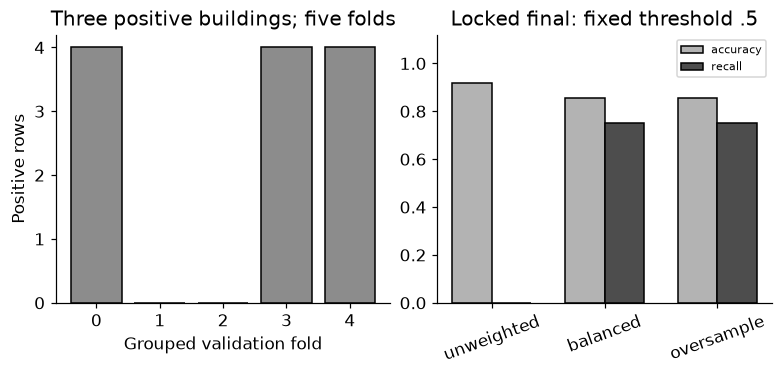

In [2]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,brier_score_loss
g=np.repeat(np.arange(50),12);within=np.tile(np.arange(12),50);y=(np.isin(g,[0,1,2,36,43,47])&(within<4)).astype(int);X=rng.normal(size=(600,3));X[:,0]+=1.5*y;train=np.flatnonzero(g<36);development=np.flatnonzero((g>=36)&(g<42));final=np.flatnonzero(g>=42)
assert [int(y[k].sum()) for k in [train,development,final]]==[12,4,8]
def metrics(ids,p):
 pred=p>=.5;truth=y[ids];positives=int(truth.sum());tp=int(np.sum(pred&(truth==1)));fp=int(np.sum(pred&(truth==0)))
 return {'rows':len(ids),'positive_rows':positives,'positive_buildings':len(np.unique(g[ids][truth==1])),'accuracy':float(accuracy_score(truth,pred)),'recall':tp/positives if positives else None,'precision':tp/(tp+fp) if tp+fp else None,'false_positives':fp,'true_positives':tp,'brier':float(brier_score_loss(truth,p))}
def fit_predict(tr,te,method,seed):
 assert not set(tr)&set(te) and not set(g[tr])&set(g[te]);scaler=StandardScaler().fit(X[tr]);a=scaler.transform(X[tr]);indices=np.arange(len(tr))
 if method=='oversample':
  local=np.random.default_rng(seed);pos=np.flatnonzero(y[tr]==1);neg=np.flatnonzero(y[tr]==0);assert len(pos)>0;indices=np.r_[neg,local.choice(pos,len(neg),replace=True)]
 assert set(tr[indices])<=set(tr)
 model=LogisticRegression(C=1,class_weight='balanced' if method=='balanced' else None,max_iter=1000).fit(a[indices],y[tr][indices]);return model.predict_proba(scaler.transform(X[te]))[:,1]
folds=list(StratifiedGroupKFold(5,shuffle=True,random_state=SEED).split(X[train],y[train],g[train]));fold_counts=[]
for tr,va in folds:
 assert not set(g[train[tr]])&set(g[train[va]]);fold_counts.append({'validation_rows':len(va),'positive_rows':int(y[train[va]].sum()),'positive_buildings':len(np.unique(g[train[va]][y[train[va]]==1]))})
assert sum(r['positive_rows']==0 for r in fold_counts)>=2
methods=['unweighted','balanced','oversample'];rows=[];final_predictions={};fold_metrics=[]
for method in methods:
 oof=np.full(len(train),np.nan)
 for k,(tr,va) in enumerate(folds):
  pred=fit_predict(train[tr],train[va],method,SEED+k);oof[va]=pred;fold_metrics.append({'method':method,'fold':k,**metrics(train[va],pred)})
 assert np.isfinite(oof).all();p=fit_predict(train,final,method,SEED+10);final_predictions[method]=p;rows.append({'method':method,'oof':metrics(train,oof),'final':metrics(final,p)})
RESULTS['folds']=fold_counts;RESULTS['fold_metrics']=fold_metrics;RESULTS['procedures']=rows;RESULTS['final_majority_baseline']=metrics(final,np.zeros(len(final)));RESULTS['development_unused']={'rows':72,'positives':4,'reason':'procedures and .5 threshold fixed, no selection'}
fig,axes=plt.subplots(1,2,figsize=(7,3.3));axes[0].bar(range(5),[r['positive_rows'] for r in fold_counts],color='.55',edgecolor='black');axes[0].set(xticks=range(5),xlabel='Grouped validation fold',ylabel='Positive rows',title='Three positive buildings; five folds')
for j,key in enumerate(['accuracy','recall']):axes[1].bar(np.arange(3)+(j-.5)*.35,[r['final'][key] for r in rows],width=.35,color=['.7','.3'][j],edgecolor='black',label=key)
axes[1].set(xticks=range(3),xticklabels=methods,ylim=(0,1.12),title='Locked final: fixed threshold .5');axes[1].tick_params(axis='x',labelrotation=20);axes[1].legend(fontsize=7);plt.show()


<a id="bootstrap"></a>
## Resample whole buildings and retain undefined outcomes

Resample the eight final buildings with replacement 1,000 times, preserving their rows. Summarize balanced-model recall only in draws containing a positive; count every zero-positive draw as undefined. This conditional percentile range is a descriptive sensitivity check with only two observed positive buildings. It cannot reveal unseen failure mechanisms and is not a reliable population guarantee. A row bootstrap would treat correlated within-building outcomes as more independent evidence than these data justify. Weighted loss and oversampling are alternative training procedures, not changes to final prevalence. Oversampling occurs after fitting the scaler to original fold-training rows and never duplicates a validation row.


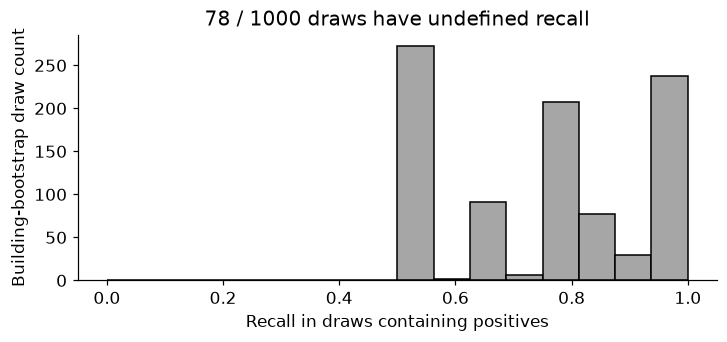

In [3]:
bootstrap_rng=np.random.default_rng(SEED+99);groups=np.unique(g[final]);recalls=[];undefined=0
for _ in range(1000):
 selected=bootstrap_rng.choice(groups,len(groups),replace=True);local=np.concatenate([np.flatnonzero(g[final]==k) for k in selected]);truth=y[final][local];pred=final_predictions['balanced'][local]>=.5
 if truth.sum()==0:undefined+=1
 else:recalls.append(float(np.sum(pred&(truth==1))/truth.sum()))
assert undefined+len(recalls)==1000 and undefined>0
RESULTS['building_bootstrap']={'draws':1000,'undefined_zero_positive_draws':undefined,'defined_draws':len(recalls),'conditional_percentiles_2_5_97_5':np.percentile(recalls,[2.5,97.5]).tolist(),'final_positive_buildings':2,'interpretation':'conditional descriptive sensitivity, not reliable population coverage'}
fig,ax=plt.subplots(figsize=(6.5,3));ax.hist(recalls,bins=np.linspace(0,1,17),color='.65',edgecolor='black');ax.set(xlabel='Recall in draws containing positives',ylabel='Building-bootstrap draw count',title=f'{undefined} / 1000 draws have undefined recall');plt.show()


In [4]:
summary={'example_id':'code_070','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['grouped stratification limits', 'training-only weights and oversampling', 'undefined rare-event metrics', 'whole-building bootstrap with missing-positive draws'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["grouped stratification limits", "training-only weights and oversampling", "undefined rare-event metrics", "whole-building bootstrap with missing-positive draws"], "elapsed_seconds": 0.291, "example_id": "code_070", "hardware": "Darwin arm64 CPU", "results": {"building_bootstrap": {"conditional_percentiles_2_5_97_5": [0.5, 1.0], "defined_draws": 922, "draws": 1000, "final_positive_buildings": 2, "interpretation": "conditional descriptive sensitivity, not reliable population coverage", "undefined_zero_positive_draws": 78}, "development_unused": {"positives": 4, "reason": "procedures and .5 threshold fixed, no selection", "rows": 72}, "final_majority_baseline": {"accuracy": 0.9166666666666666, "brier": 0.08333333333333333, "false_positives": 0, "positive_buildings": 2, "positive_rows": 8, "precision": null, "recall": 0.0, "rows": 96, "true_positives": 0}, "fold_metrics": [{"accuracy": 0.9583333333333334, "brier": 0.04074400408039767, "fal